In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
!pip install -q inference-gpu[yolo-world]==0.9.12rc1   #zero-shot object detection using YOLO-World

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.0/301.0 kB 4.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.2/59.2 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 15.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.0/92.0 kB 7.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 252.0/252.0 kB 15.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 239.7/239.7 kB 19.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 23.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 11.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.0/66.0 kB 5.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 5.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 318.6/318.6 kB 24.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━

In [ ]:
!pip install -q supervision==0.19.0rc3   #post-processing and visualizing the detected objects.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.8/90.8 kB 1.7 MB/s eta 0:00:00


In [ ]:
import cv2
import supervision as sv

from tqdm import tqdm
from inference.models.yolo_world.yolo_world import YOLOWorld

[05/04/24 14:57:43] WARNING  Your inference package version 0.9.12rc1 is out of date! Please upgrade ]8;id=843187;file:///usr/local/lib/python3.10/dist-packages/inference/core/__init__.py\__init__.py]8;;\:]8;id=335246;file:///usr/local/lib/python3.10/dist-packages/inference/core/__init__.py#35\35]8;;\
                             to version 0.9.23 of inference for the latest features and bug fixes by               
                             running `pip install --upgrade inference`.                                            

In [ ]:
#SOURCE_VIDEO_PATH = "/content/VID-20240501-WA0010.mp4"
SOURCE_IMAGE_PATH = "/content/sample_data/IMG-20240503-WA0053.jpg"

In [ ]:
model = YOLOWorld(model_id="yolo_world/l")

In [ ]:
image = cv2.imread(SOURCE_IMAGE_PATH)
classes = ["Tomato", "Potato","Cucumber","Green capsicum"]
model.set_classes(classes)

results = model.infer(image, confidence=0.2)  #41 with 0.1 , 69 with 0.5 , 99&WA0101 with 0.2 , 53 with 0.3
detections = sv.Detections.from_inference(results).with_nms(threshold=0.1)

In [ ]:
BOUNDING_BOX_ANNOTATOR = sv.BoundingBoxAnnotator(thickness=2)
LABEL_ANNOTATOR = sv.LabelAnnotator(text_thickness=2, text_scale=1, text_color=sv.Color.BLACK)

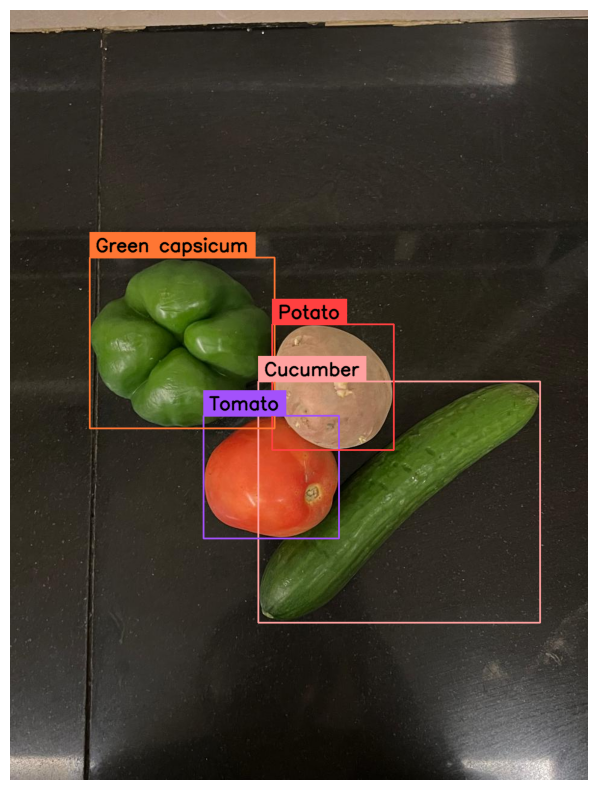

In [ ]:
annotated_image = image.copy()
annotated_image = BOUNDING_BOX_ANNOTATOR.annotate(annotated_image, detections)
annotated_image = LABEL_ANNOTATOR.annotate(annotated_image, detections)
sv.plot_image(annotated_image, (10, 10))

In [ ]:
# Initialize an empty list to store detected class names
detected_classes = []

# Iterate over detections to extract class names
for detection in detections:
    # Check if the detection format is valid
    if isinstance(detection, tuple) and len(detection) >= 2:
        # Extract class name from the dictionary within the detection tuple
        class_name = detection[-1]['class_name']

        # Append the class name to the list of detected classes
        detected_classes.append(class_name)
    else:
        print("Invalid detection format")

# Print the list of detected classes
print("Detected classes:", detected_classes)


Detected classes: ['Cucumber', 'Tomato', 'Potato', 'Green capsicum']


In [ ]:
# Define pricing dictionary for each item
pricing = {
    "Tomato": 12.50,
    "Potato": 10.50,
    "Cucumber": 10.00,
    "Green capsicum": 13.00
}

# Initialize total bill
total_bill = 0.0

# Iterate over detected classes to calculate total bill
for detected_class in detected_classes:
    # Lookup price for the detected class in the pricing dictionary
    price = pricing.get(detected_class)

    # Check if the price exists
    if price is not None:
        total_bill += price
    else:
        print(f"Price not found for {detected_class}")

# Print the total bill
print("Total bill:", total_bill)


Total bill: 46.0
